# Week 3 - Support Vector Machines
## Exercise 1: Red Wine Quality Prediction

**Objective:** predict wine quality (`quality`) from physicochemical attributes
using Support Vector Machines.

**Dataset:** Red Wine Quality (Cortez et al., 2009), 1,599 observations of
*vinho verde* red wine, 11 continuous predictors and 1 ordinal target.

---
### 1.1 Dataset Overview & Variable Study

All predictors are continuous (`float64`). The target `quality` is stored as
`int64` but is **ordinal** (scores from 3 to 8).

| Variable | Description |
|---|---|
| `fixed acidity` | Non-volatile acids (mainly tartaric) |
| `volatile acidity` | Acetic acid; high levels give a vinegar taste |
| `citric acid` | Adds freshness |
| `residual sugar` | Sugar left after fermentation |
| `chlorides` | Salt content |
| `free sulfur dioxide` / `total sulfur dioxide` | Free and total SO₂ (preservative) |
| `density` | Wine density |
| `pH` | Acidity level |
| `sulphates` | Antimicrobial additive (potassium sulphate) |
| `alcohol` | Alcohol percentage by volume |

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def load_wine_data(path: str) -> pd.DataFrame:
    """Load the red wine dataset and print a structural summary.

    Args:
        path: Path to the CSV file.

    Returns:
        DataFrame with the raw data.
    """
    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print(df.dtypes)
    display(df.describe().T)
    return df


df = load_wine_data("winequality-red.csv")

Shape: (1599, 12)
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


### 1.2 Distribution Analysis

We inspect the distribution of every variable with histograms.

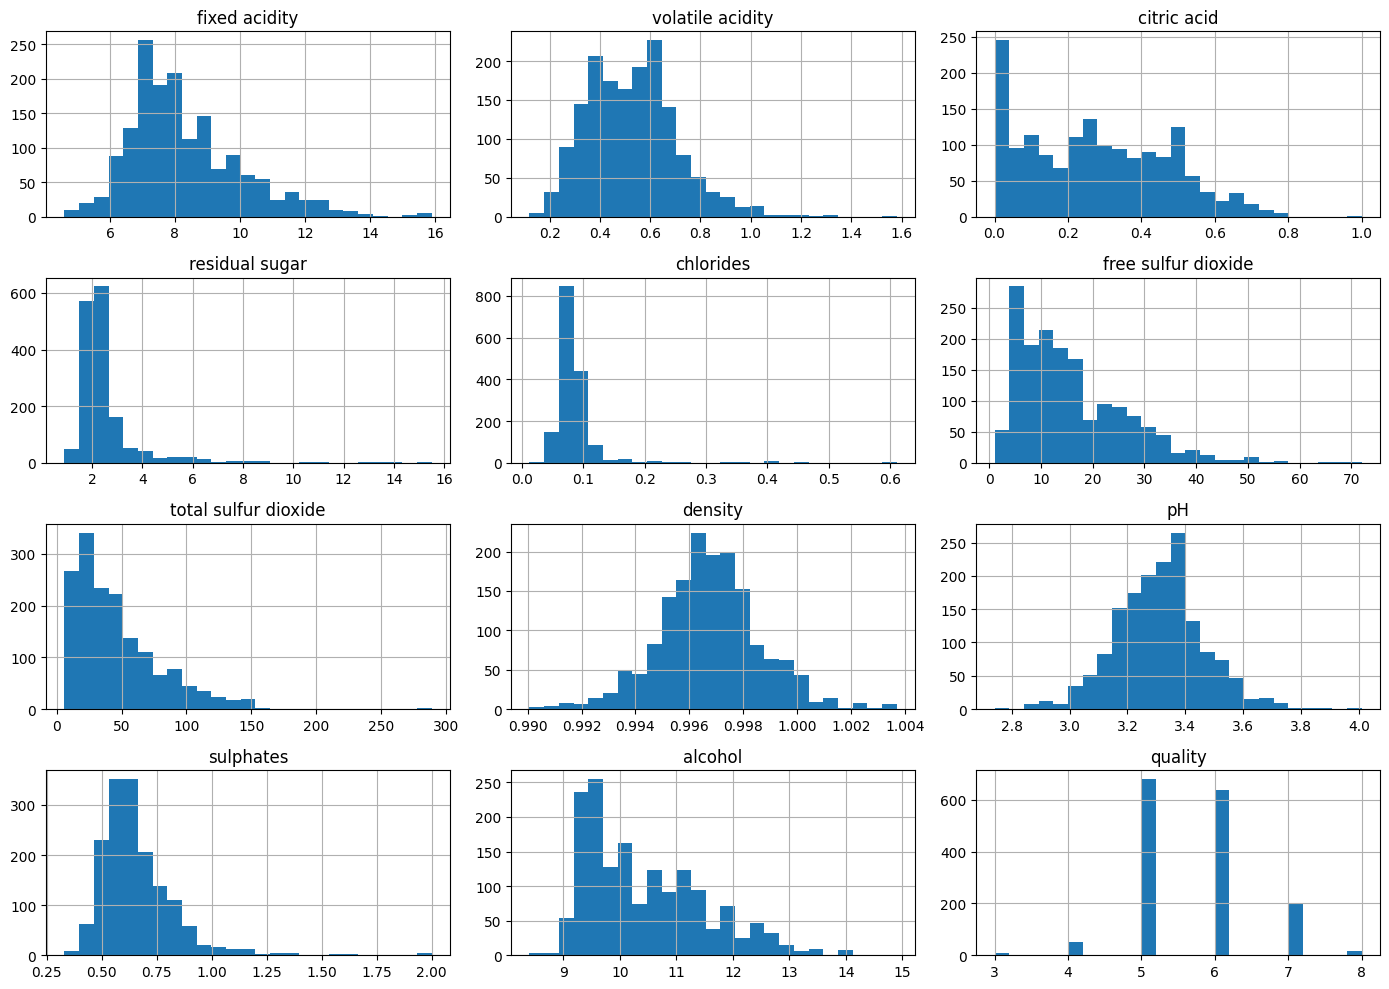

In [3]:
df.hist(bins=25, figsize=(14, 10))
plt.tight_layout()
plt.show()

**Key Insights**
- `residual sugar` and `chlorides` are **right-skewed**, with marked outliers.
- `quality` is **imbalanced**: most wines fall in classes 5 and 6, with very
  few samples in classes 3 and 8.
- Scales differ widely across variables (e.g. `total sulfur dioxide` vs
  `density`), so **feature scaling** is required before training an SVM,
  since this model relies on distances and inner products.

In [ ]:
def plot_correlations(df: pd.DataFrame, target: str = "quality") -> pd.Series:
    """Plot the Pearson correlation matrix and rank features by target correlation.

    Args:
        df: DataFrame with numeric columns.
        target: Name of the target column.

    Returns:
        Series of correlations with the target, sorted in descending order.
    """
    corr = df.corr()
    plt.figure(figsize=(11, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Matrix - Red Wine")
    plt.show()
    return corr[target].drop(target).sort_values(ascending=False)


print(plot_correlations(df))

**Key Insights**
- **Against the target:** `alcohol` (positive, strongest) and
  `volatile acidity` (negative) are the best individual predictors.
  `sulphates` and `citric acid` add weaker positive signal.
- **Among predictors (multicollinearity):** `fixed acidity` is strongly
  correlated with `citric acid`, `density` and `pH` (negative), which
  indicates redundant information.
- **Decision:** using `alcohol` as the single predictor in the next step is
  supported by its correlation with `quality`.

### 1.4 Data Cleaning

We check for missing values and duplicated rows.

In [ ]:
def remove_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    """Drop duplicated rows, keeping the first occurrence.

    Args:
        df: Raw DataFrame.

    Returns:
        DataFrame without duplicates and with a reset index.
    """
    print("Missing values:", df.isna().sum().sum())
    print("Duplicated rows:", df.duplicated().sum())
    return df.drop_duplicates(keep="first").reset_index(drop=True)


df_clean = remove_duplicates(df)
print("Shape after cleaning:", df_clean.shape)

**Key Insights**
- There are **no missing values**, so no imputation is needed.
- **240 duplicated rows** were found and removed (keeping the first
  occurrence). Keeping them would cause **data leakage** (the same
  observation in both train and test) and over-optimistic metrics.
  Final shape: **[X] rows × 12 columns**.
- Outliers in `residual sugar` and `chlorides` are **not removed**: they are
  physically plausible measurements and are mitigated through feature scaling.

### Modeling Decision
Since `quality` is **ordinal** and some classes have very few samples, we opt
for **SVR (regression)**. This preserves the order of the scale and avoids
treating every class error as equivalent.